# Лабораторная работа 3. Градиентный спуск

**Вариант:** 7 (нечётный → L2-регуляризация)

### Задание 1
Сгенерировать датасет при помощи `sklearn.datasets.make_regression` (не менее 2 признаков без учёта целевого, т.е. не менее 3 весов с учётом свободного члена). При необходимости выполнить масштабирование данных.

In [1]:
import numpy as np                                   # NumPy: работа с массивами и матрицами, математика
import pandas as pd                                  # pandas: таблицы (DataFrame)
import matplotlib.pyplot as plt                      # matplotlib: построение графиков
from sklearn.datasets import make_regression         # генератор синтетического набора данных для регрессии
from sklearn.model_selection import train_test_split # разбиение данных на обучающую и тестовую части
from sklearn.preprocessing import StandardScaler     # стандартизация (среднее 0, стандартное отклонение 1)

RANDOM_STATE = 42                                    # фиксируем «зерно» случайности, чтобы результаты повторялись
np.set_printoptions(precision=4, suppress=True)      # печатать числа NumPy с 4 знаками и без научной записи

In [2]:
# 3 признака + целевая переменная; coef=True вернёт истинные веса, по которым сгенерирована y
X, y, true_coef = make_regression(                   # X - матрица признаков, y - целевая переменная, true_coef - истинные веса
    n_samples=500,                                   # число объектов (строк) в датасете
    n_features=3,                                    # число признаков (по условию не меньше 2)
    n_informative=3,                                 # сколько признаков реально влияют на y (все три)
    noise=10,                                        # величина случайного шума, добавляемого к y
    bias=5,                                          # свободный член (сдвиг) в истинной зависимости
    coef=True,                                       # дополнительно вернуть истинные веса признаков
    random_state=RANDOM_STATE,                       # фиксируем генерацию для воспроизводимости
)

print('X:', X.shape, ' y:', y.shape)                 # размеры: (500, 3) и (500,)
print('Истинные веса:', true_coef, ' bias = 5')      # веса, которые мы потом попробуем «найти» градиентным спуском

df = pd.DataFrame(X, columns=['x1', 'x2', 'x3'])     # собираем признаки в таблицу с понятными именами столбцов
df['y'] = y                                          # добавляем столбец с целевой переменной
df.head()                                            # показываем первые 5 строк таблицы

X: (500, 3)  y: (500,)
Истинные веса: [26.9821 82.5049 49.8256]  bias = 5


,x1,x2,x3,y
0,-0.825497,-0.321386,0.412931,-26.819734
1,-1.146345,0.302635,-0.754276,-50.378137
2,-1.377669,-0.937825,0.515035,-84.981142
3,0.599929,1.530751,1.218762,184.009877
4,0.638730,-1.143005,1.633432,20.420390


In [3]:
df.describe().round(3)                               # сводная статистика (среднее, std, min, max и т.д.), округлённая до 3 знаков

,x1,x2,x3,y
count,500.000,500.000,500.000,500.000
mean,0.115,-0.028,0.060,8.657
std,0.938,0.999,1.028,101.920
min,-2.896,-3.241,-2.849,-313.544
25%,-0.553,-0.731,-0.594,-59.496
50%,0.127,-0.037,0.069,6.304
75%,0.667,0.661,0.709,80.043
max,2.580,3.079,3.853,323.567


Признаки `make_regression` уже близки к стандартному нормальному распределению, а целевая переменная имеет масштаб в сотни единиц. Градиентный спуск чувствителен к масштабу (от него зависит допустимый шаг обучения), поэтому стандартизируем и признаки, и целевую переменную. Сначала делим выборку на обучающую и тестовую, и только затем считаем параметры масштабирования по обучающей части, чтобы не было утечки информации из теста.

In [4]:
X_train, X_test, y_train, y_test = train_test_split( # делим данные на обучающую и тестовую части
    X, y, test_size=0.2, random_state=RANDOM_STATE       # 20% объектов уходит в тест, разбиение воспроизводимое
)

x_scaler = StandardScaler()                          # создаём стандартизатор для признаков
X_train_s = x_scaler.fit_transform(X_train)          # считаем среднее и std ТОЛЬКО по train и сразу применяем к train
X_test_s = x_scaler.transform(X_test)                # к тесту применяем те же среднее и std (без повторного подсчёта)

y_scaler = StandardScaler()                          # отдельный стандартизатор для целевой переменной
y_train_s = y_scaler.fit_transform(y_train.reshape(-1, 1)).ravel()  # reshape нужен, т.к. скейлер ждёт 2D; ravel возвращает 1D
y_test_s = y_scaler.transform(y_test.reshape(-1, 1)).ravel()        # то же преобразование для y теста

print('Размеры train/test:', X_train_s.shape, X_test_s.shape)  # проверяем размеры: (400, 3) и (100, 3)
print('Среднее признаков (train):', X_train_s.mean(axis=0).round(6))  # после стандартизации средние должны быть ≈ 0
print('Std признаков (train):   ', X_train_s.std(axis=0).round(6))    # а стандартные отклонения ≈ 1
print('Среднее/std y (train):   ', y_train_s.mean().round(6), y_train_s.std().round(6))  # то же для y

Размеры train/test: (400, 3) (100, 3)
Среднее признаков (train): [0. 0. 0.]
Std признаков (train):    [1. 1. 1.]
Среднее/std y (train):    0.0 1.0


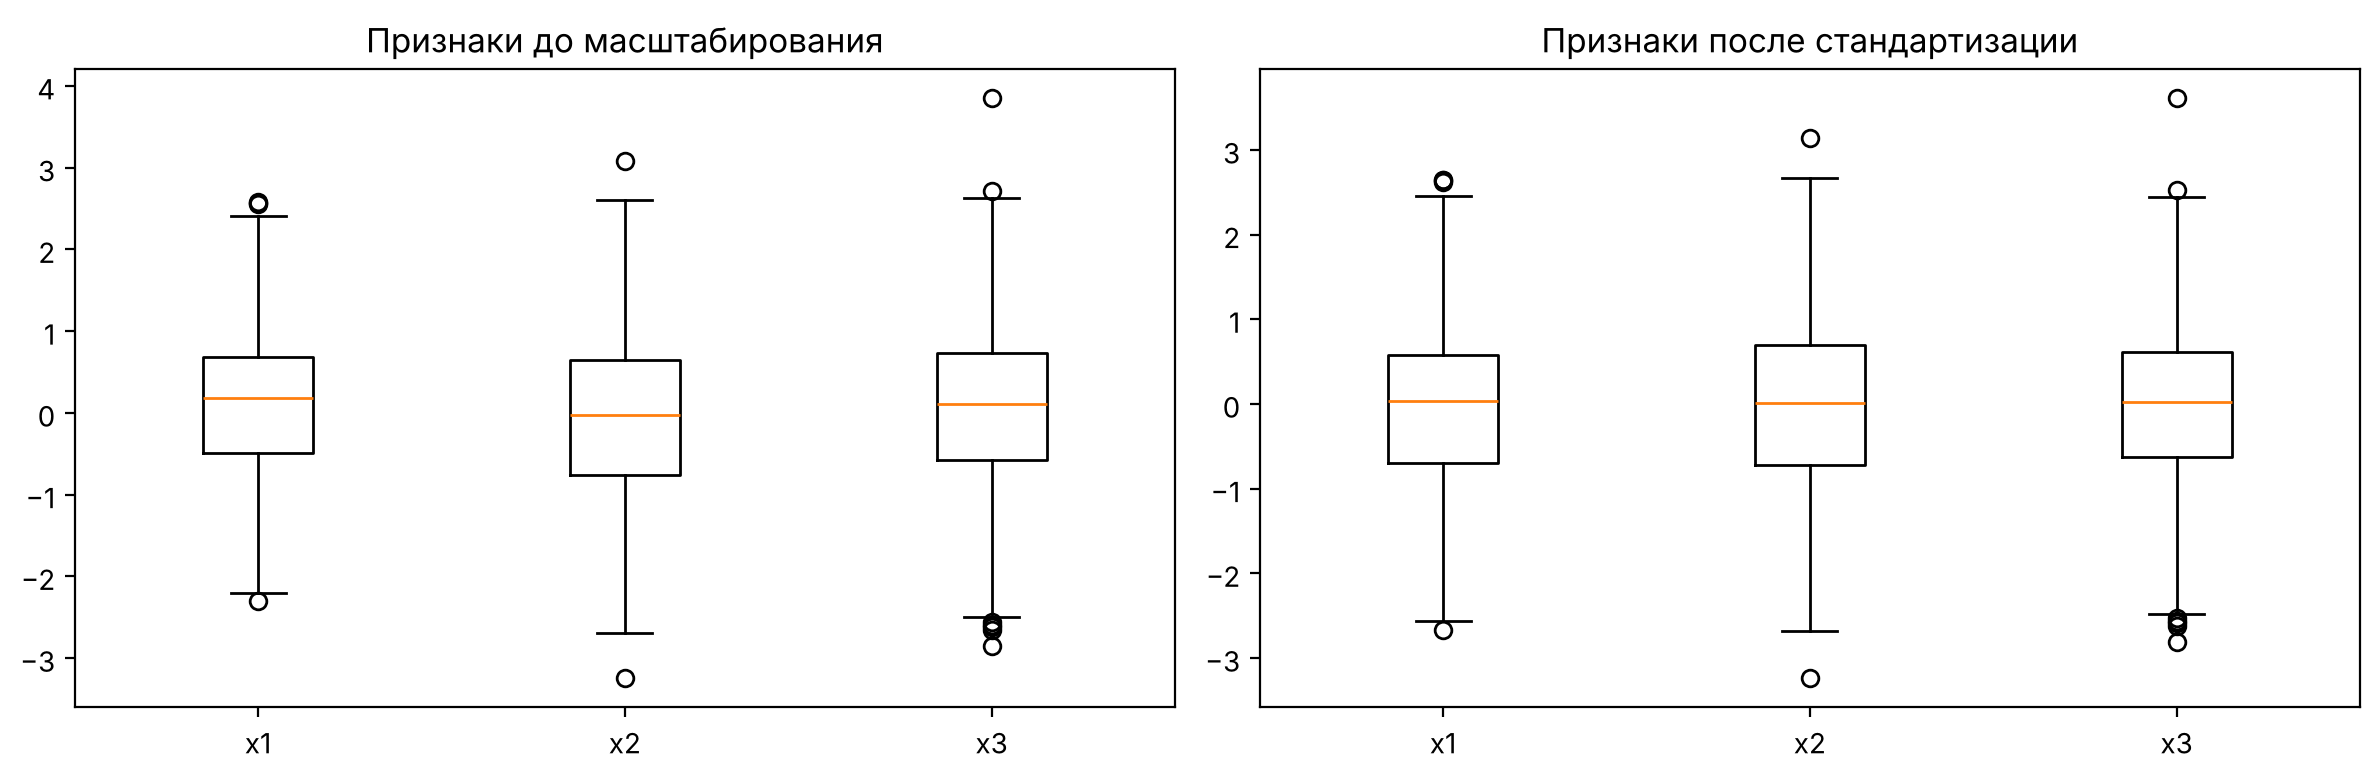

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))    # рисунок с двумя графиками в ряд
axes[0].boxplot(X_train, tick_labels=['x1', 'x2', 'x3'])      # «ящики с усами» для исходных признаков
axes[0].set_title('Признаки до масштабирования')              # заголовок левого графика
axes[1].boxplot(X_train_s, tick_labels=['x1', 'x2', 'x3'])    # то же для стандартизованных признаков
axes[1].set_title('Признаки после стандартизации')            # заголовок правого графика
plt.tight_layout()                                            # аккуратно расставить элементы, чтобы не накладывались
plt.show()                                                    # вывести график

### Задание 2
Написать самостоятельно функцию градиентного спуска (не стохастического) по алгоритму:
1. инициализировать начальные веса и ε;
2. организовать цикл по количеству итераций;
3. рассчитать новые веса;
4. завершить цикл, если $\|w_{new} - w_{old}\| < \varepsilon$.

Модель линейная: $\hat y = w_0 + w_1 x_1 + w_2 x_2 + w_3 x_3$, функция потерь — MSE: $L(w)=\frac1n\sum_i (\hat y_i - y_i)^2$, её градиент $\nabla L = \frac2n X^T(Xw - y)$. Новые веса: $w_{new} = w - \eta \nabla L$, где $\eta$ — скорость обучения. Свободный член учитывается столбцом из единиц.

In [6]:
def gradient_descent(X, y, learning_rate=0.1, max_iter=1000, epsilon=1e-8):
    # X - признаки, y - целевая переменная, learning_rate - шаг (скорость обучения),
    # max_iter - максимум итераций, epsilon - порог остановки
    # столбец единиц для свободного члена w0
    Xb = np.column_stack([np.ones(len(X)), X])       # добавляем слева столбец из единиц: тогда w0 умножается на 1
    # 1. начальные веса (нули) и epsilon
    w = np.zeros(Xb.shape[1])                        # стартовые веса: все нули (w0, w1, w2, w3)
    mse_history = [np.mean((Xb @ w - y) ** 2)]       # список ошибок MSE по итерациям; первая - на нулевых весах
    # 2. цикл по количеству итераций
    for i in range(max_iter):                        # повторяем не больше max_iter раз
        # 3. расчёт новых весов
        grad = 2 / len(y) * Xb.T @ (Xb @ w - y)      # градиент MSE: (2/n) * X^T * (предсказание - y)
        w_new = w - learning_rate * grad             # шаг против градиента: новые веса
        mse_history.append(np.mean((Xb @ w_new - y) ** 2))  # сохраняем MSE с новыми весами
        # 4. условие остановки
        converged = np.linalg.norm(w_new - w) < epsilon     # веса почти не изменились (длина изменения < epsilon)?
        w = w_new                                    # принимаем новые веса
        if converged:                                # если сошлись -
            break                                    # выходим из цикла досрочно
    return w, mse_history                            # возвращаем найденные веса и историю ошибки

Число итераций: 77
Веса GD: [-0.      0.2412  0.8115  0.5138]
Итоговая MSE (train, масштабированная): 0.009287


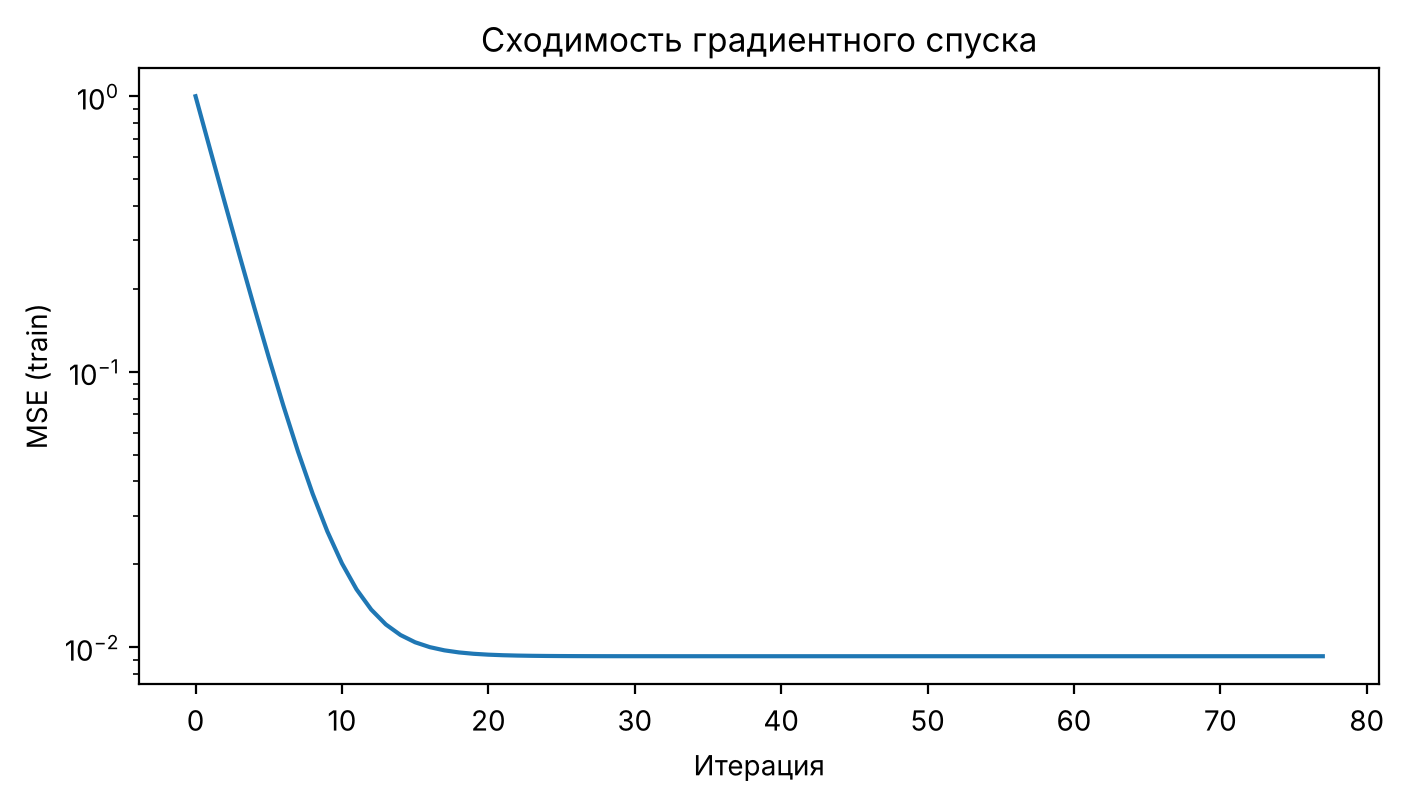

In [7]:
w_gd, mse_gd = gradient_descent(X_train_s, y_train_s, learning_rate=0.1, max_iter=1000, epsilon=1e-8)  # запускаем наш GD
print('Число итераций:', len(mse_gd) - 1)           # в истории на 1 элемент больше (начальная ошибка), поэтому -1
print('Веса GD:', w_gd)                              # найденные веса [w0, w1, w2, w3]
print('Итоговая MSE (train, масштабированная):', round(mse_gd[-1], 6))  # ошибка в конце обучения

plt.figure(figsize=(8, 4))                           # новый график 8x4 дюйма
plt.plot(mse_gd)                                     # линия: MSE по итерациям
plt.yscale('log')                                    # логарифмическая шкала по Y, чтобы видеть малые значения ошибки
plt.xlabel('Итерация')                               # подпись оси X
plt.ylabel('MSE (train)')                            # подпись оси Y
plt.title('Сходимость градиентного спуска')          # заголовок графика
plt.show()                                           # показать график

Проверка корректности: сравним найденные веса с аналитическим решением МНК (`LinearRegression`) на тех же масштабированных данных.

In [8]:
from sklearn.linear_model import LinearRegression  # готовая линейная регрессия (аналитическое решение МНК)
from sklearn.metrics import mean_squared_error       # функция вычисления среднеквадратичной ошибки

lr = LinearRegression().fit(X_train_s, y_train_s)    # обучаем эталонную модель на тех же данных
w_ols = np.r_[lr.intercept_, lr.coef_]               # склеиваем свободный член и веса в один вектор, как у нашего GD
print('Веса МНК:', w_ols)                            # эталонные веса
print('Веса GD: ', w_gd)                             # веса, найденные нашим градиентным спуском
print('Макс. отклонение:', np.abs(w_gd - w_ols).max())  # наибольшая разница между весами (должна быть почти 0)

pred = np.column_stack([np.ones(len(X_test_s)), X_test_s]) @ w_gd  # предсказания GD на тесте (с добавленным столбцом единиц)
print('MSE на test (масштабированная):', round(mean_squared_error(y_test_s, pred), 6))  # ошибка на отложенной выборке

Веса МНК: [-0.      0.2412  0.8115  0.5138]
Веса GD:  [-0.      0.2412  0.8115  0.5138]
Макс. отклонение: 2.965242218433417e-08
MSE на test (масштабированная): 0.010075


### Задание 3
Поэкспериментировать со скоростью обучения $\eta$. Запустим градиентный спуск с одинаковыми начальными весами, лимитом итераций и ε для набора значений $\eta$ от очень малых до заведомо слишком больших.

In [9]:
learning_rates = [0.001, 0.01, 0.1, 0.5, 0.9, 1.0, 1.05]  # набор проверяемых скоростей обучения
lr_results = {}                                      # словарь: скорость обучения -> история MSE
rows = []                                            # строки итоговой таблицы
with np.errstate(all='ignore'):                      # отключаем предупреждения о переполнении (при расходимости числа огромные)
    for eta in learning_rates:                       # перебираем скорости обучения
        w, hist = gradient_descent(X_train_s, y_train_s, learning_rate=eta, max_iter=1000, epsilon=1e-8)  # запуск GD
        lr_results[eta] = hist                       # запоминаем историю ошибки для графика
        n_iter = len(hist) - 1                       # сколько итераций выполнено
        final = hist[-1]                             # итоговая ошибка
        if not np.isfinite(final) or final > hist[0]:  # ошибка стала бесконечной или больше начальной -
            status = 'расходится'                    # метод расходится
        elif n_iter < 1000:                          # остановились раньше лимита -
            status = 'сошёлся'                       # метод сошёлся по критерию epsilon
        else:                                        # дошли до лимита итераций -
            status = 'лимит итераций'                # не успел сойтись
        rows.append({'lr': eta, 'итераций': n_iter, 'итоговая MSE': final,
                     'откл. от МНК': np.abs(w - w_ols).max(), 'статус': status})  # добавляем строку в таблицу

pd.DataFrame(rows)                                   # выводим результаты в виде таблицы

,lr,итераций,итоговая MSE,откл. от МНК,статус
0,0.001,1000,2.667088e-02,1.083599e-01,лимит итераций
1,0.010,718,9.287279e-03,4.115113e-07,сошёлся
2,0.100,77,9.287279e-03,2.965242e-08,сошёлся
3,0.500,7,9.287279e-03,2.259534e-11,сошёлся
4,0.900,120,9.287279e-03,2.914521e-09,сошёлся
5,1.000,1000,9.290306e+49,6.988016e+24,расходится
6,1.050,1000,3.394200e+130,1.335696e+65,расходится


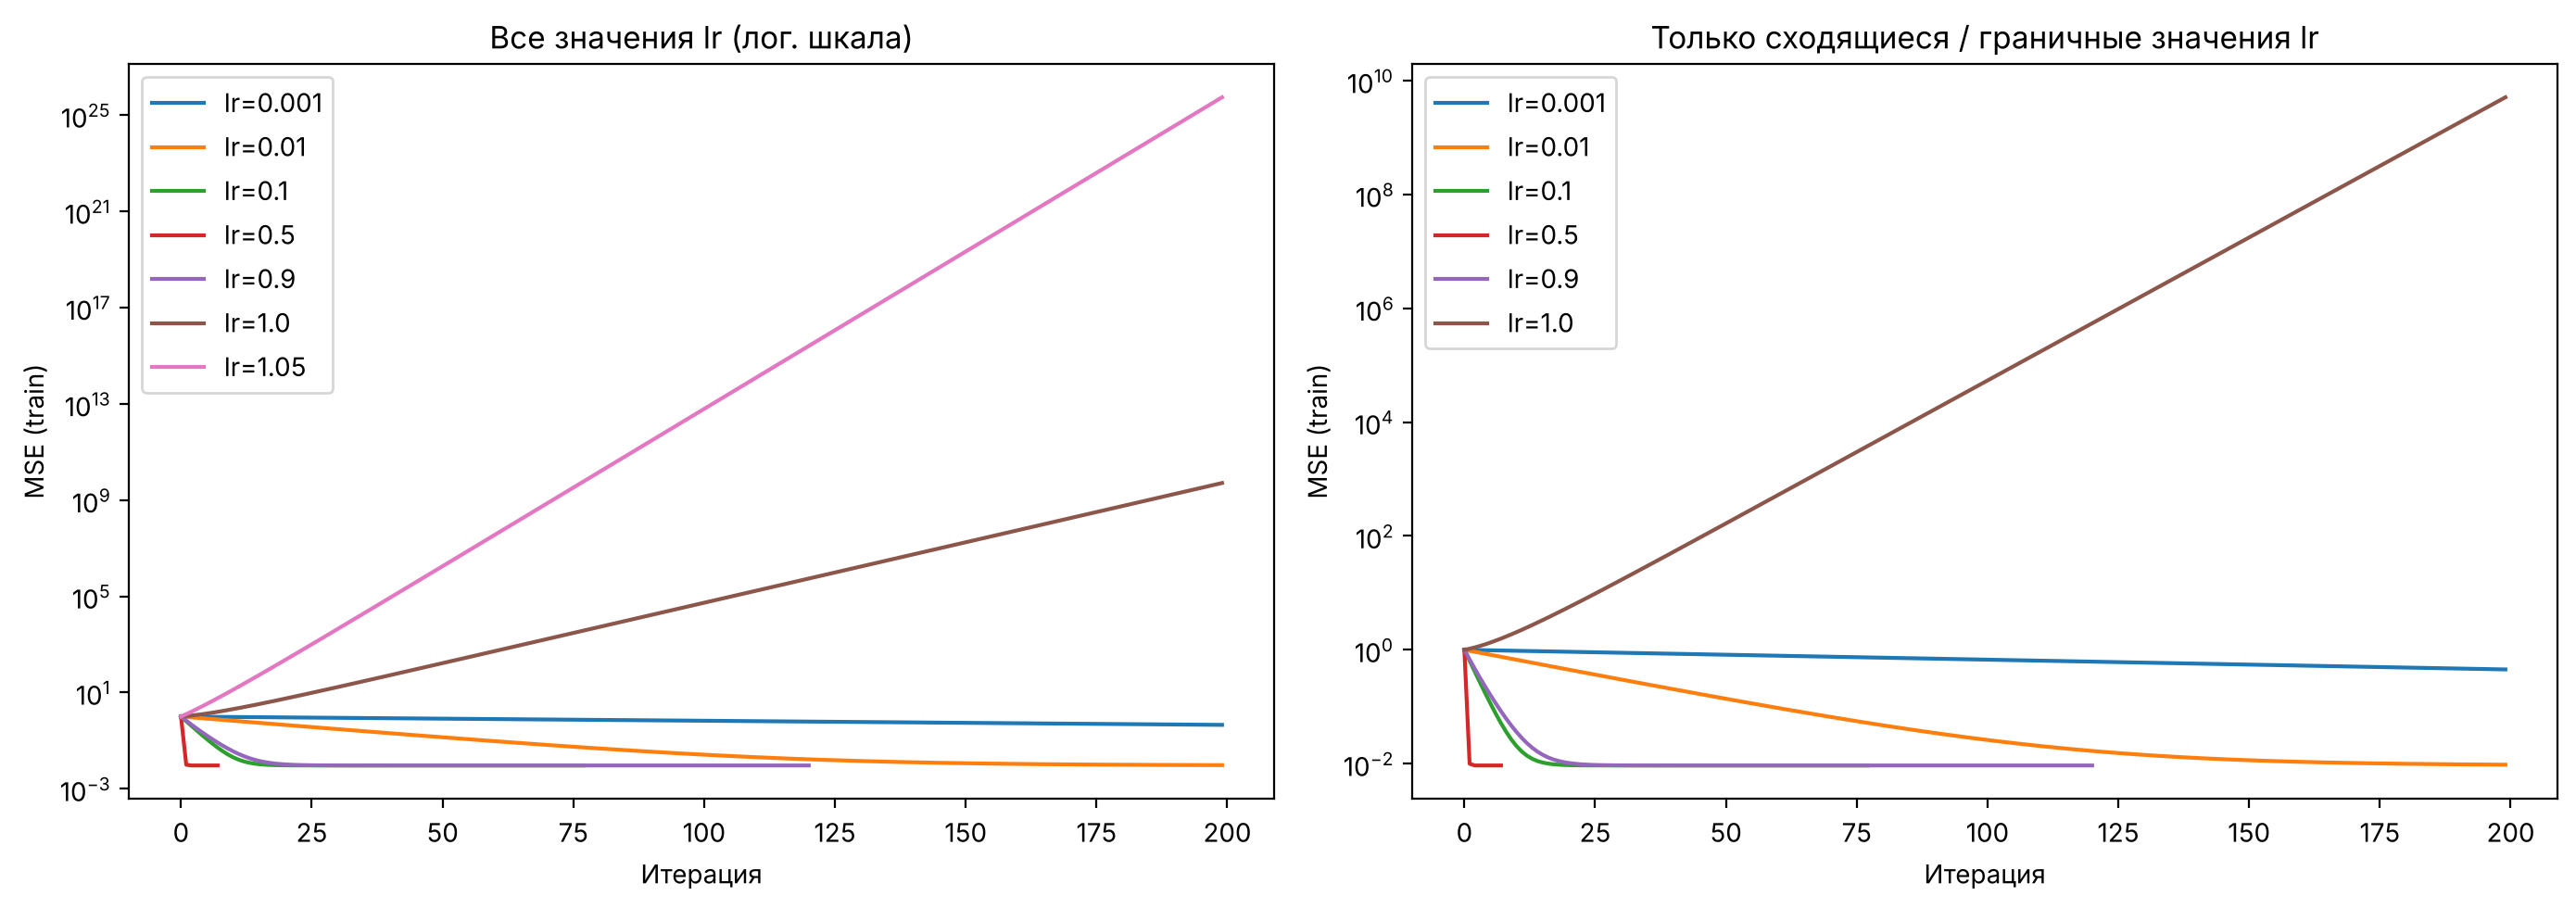

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # два графика в ряд
for eta, hist in lr_results.items():                 # перебираем результаты по каждой скорости обучения
    h = np.array(hist)                               # история ошибки как массив
    axes[0].plot(h[:200], label=f'lr={eta}')         # на левый график - первые 200 итераций для всех lr
    if eta <= 1.0:                                   # на правый график - только lr, которые не расходятся
        axes[1].plot(h[:200], label=f'lr={eta}')
axes[0].set_yscale('log')                            # логарифмическая шкала по Y (иначе расходящиеся «сломают» график)
axes[0].set_title('Все значения lr (лог. шкала)')    # заголовок левого графика
axes[1].set_yscale('log')                            # логарифмическая шкала для правого графика
axes[1].set_title('Только сходящиеся / граничные значения lr')  # заголовок правого графика
for ax in axes:                                      # общие настройки для обоих графиков
    ax.set_xlabel('Итерация')                        # подпись оси X
    ax.set_ylabel('MSE (train)')                     # подпись оси Y
    ax.legend()                                      # легенда (какая линия какому lr соответствует)
plt.tight_layout()                                   # расставить элементы без наложений
plt.show()                                           # показать графики

**Выводы по заданию 3**

- $\eta = 0.001$ — слишком мало: за лимит в 1000 итераций метод не дошёл до минимума (MSE 0.027 против 0.0093, веса отличаются от МНК на ≈0.11).
- $\eta = 0.01$ и $0.1$ сходятся к тому же решению, что и МНК, но за 718 и 77 итераций соответственно: чем больше шаг (в допустимых пределах), тем быстрее сходимость.
- $\eta = 0.5$ — оптимум в эксперименте, всего 7 итераций. Гессиан MSE равен $\frac2n X^TX \approx 2I$ (признаки стандартизованы и почти некоррелированы), поэтому шаг $\eta \approx 1/2$ почти «перепрыгивает» сразу в минимум.
- $\eta = 0.9$ — шаг уже слишком велик: траектория колеблется вокруг минимума (знак ошибки меняется на каждой итерации), и на сходимость уходит 120 итераций, больше, чем при 0.5.
- $\eta \ge 1.0$ — расходимость: условие устойчивости для квадратичной функции $\eta < 2/\lambda_{max}$, а здесь $\lambda_{max} \approx 2$, т.е. порог около 1. Ошибка растёт экспоненциально.

Итого: слишком малая скорость обучения даёт медленную сходимость, слишком большая — колебания и расходимость; масштабирование признаков упрощает выбор шага, так как $\lambda_{max}$ становится порядка единицы.

### Задание 4
Добавить в функцию выбор случайного объекта на каждой итерации, чтобы получить стохастический градиентный спуск (SGD). Теперь градиент считается не по всей выборке, а по одному случайно выбранному объекту $i$:

$\nabla L_i = 2\,x_i\,(x_i^T w - y_i)$, $\quad w_{new} = w - \eta \nabla L_i$.

Для сопоставления с пакетным методом после каждой итерации сохраняем MSE по всей обучающей выборке.

In [11]:
def stochastic_gradient_descent(X, y, learning_rate=0.01, max_iter=5000, epsilon=1e-8, seed=RANDOM_STATE):
    # то же, что gradient_descent, но градиент считается по ОДНОМУ случайному объекту
    rng = np.random.default_rng(seed)                # генератор случайных чисел (с зерном для воспроизводимости)
    Xb = np.column_stack([np.ones(len(X)), X])       # столбец единиц для свободного члена
    # 1. начальные веса и epsilon
    w = np.zeros(Xb.shape[1])                        # стартовые веса - нули
    mse_history = [np.mean((Xb @ w - y) ** 2)]       # история MSE по ВСЕЙ выборке (для сравнения с GD)
    # 2. цикл по количеству итераций
    for i in range(max_iter):                        # каждая итерация - одно обновление весов
        # выбор случайного объекта
        j = rng.integers(len(y))                     # случайный номер объекта от 0 до n-1
        # 3. расчёт новых весов по градиенту одного объекта
        grad = 2 * Xb[j] * (Xb[j] @ w - y[j])        # градиент ошибки только на объекте j
        w_new = w - learning_rate * grad             # шаг против этого (шумного) градиента
        mse_history.append(np.mean((Xb @ w_new - y) ** 2))  # считаем MSE по всей выборке для графика
        # 4. условие остановки
        converged = np.linalg.norm(w_new - w) < epsilon     # веса почти не изменились?
        w = w_new                                    # принимаем новые веса
        if converged:                                # если сошлись -
            break                                    # останавливаемся
    return w, mse_history                            # возвращаем веса и историю ошибки

Число итераций: 5000
Веса SGD: [0.0053 0.2453 0.821  0.5107]
Веса МНК: [-0.      0.2412  0.8115  0.5138]
Макс. отклонение от МНК: 0.009577465648775263
Итоговая MSE (train): 0.00943  (МНК: 0.009287 )


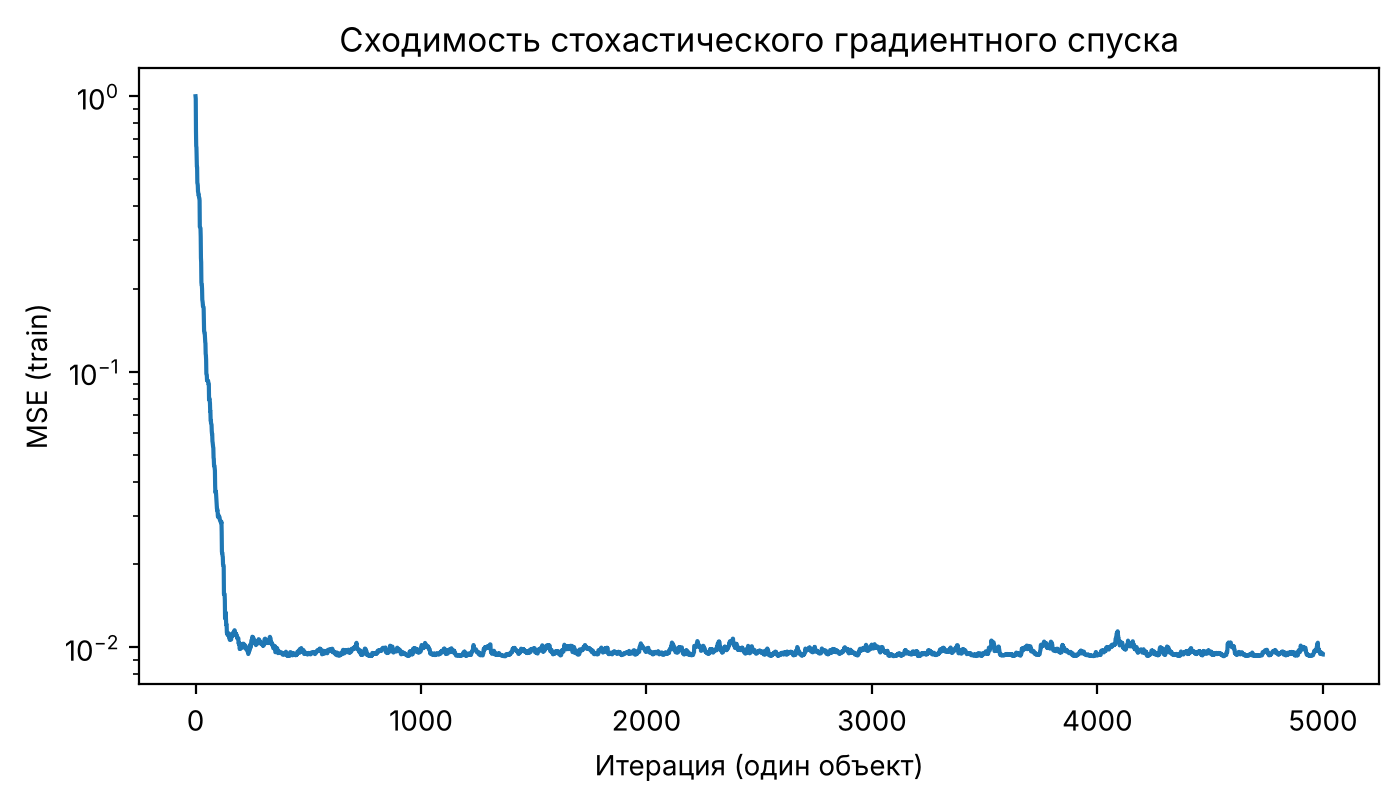

In [12]:
w_sgd, mse_sgd = stochastic_gradient_descent(X_train_s, y_train_s, learning_rate=0.01, max_iter=5000)  # запускаем SGD
print('Число итераций:', len(mse_sgd) - 1)          # сколько обновлений выполнено
print('Веса SGD:', w_sgd)                            # найденные веса
print('Веса МНК:', w_ols)                            # эталонные веса для сравнения
print('Макс. отклонение от МНК:', np.abs(w_sgd - w_ols).max())  # наибольшая разница с эталоном
print('Итоговая MSE (train):', round(mse_sgd[-1], 6), ' (МНК:', round(mean_squared_error(y_train_s, lr.predict(X_train_s)), 6), ')')  # ошибка SGD и минимально возможная (МНК)

plt.figure(figsize=(8, 4))                           # новый график
plt.plot(mse_sgd)                                    # MSE по итерациям
plt.yscale('log')                                    # логарифмическая шкала по Y
plt.xlabel('Итерация (один объект)')                 # подпись оси X
plt.ylabel('MSE (train)')                            # подпись оси Y
plt.title('Сходимость стохастического градиентного спуска')  # заголовок
plt.show()                                           # показать график

### Задание 5
Обучить линейную модель при помощи градиентного и стохастического градиентного спуска, нанести среднеквадратичную ошибку обоих методов на один график и сделать выводы о скорости сходимости.

Пакетный GD делает одно обновление за итерацию, но тратит на него проход по всей выборке; SGD делает одно обновление за один объект. Поэтому сравним методы по двум осям: по числу обновлений весов и по числу эпох (одна эпоха = проход по $n=400$ объектам, т.е. 1 итерация GD или 400 итераций SGD).

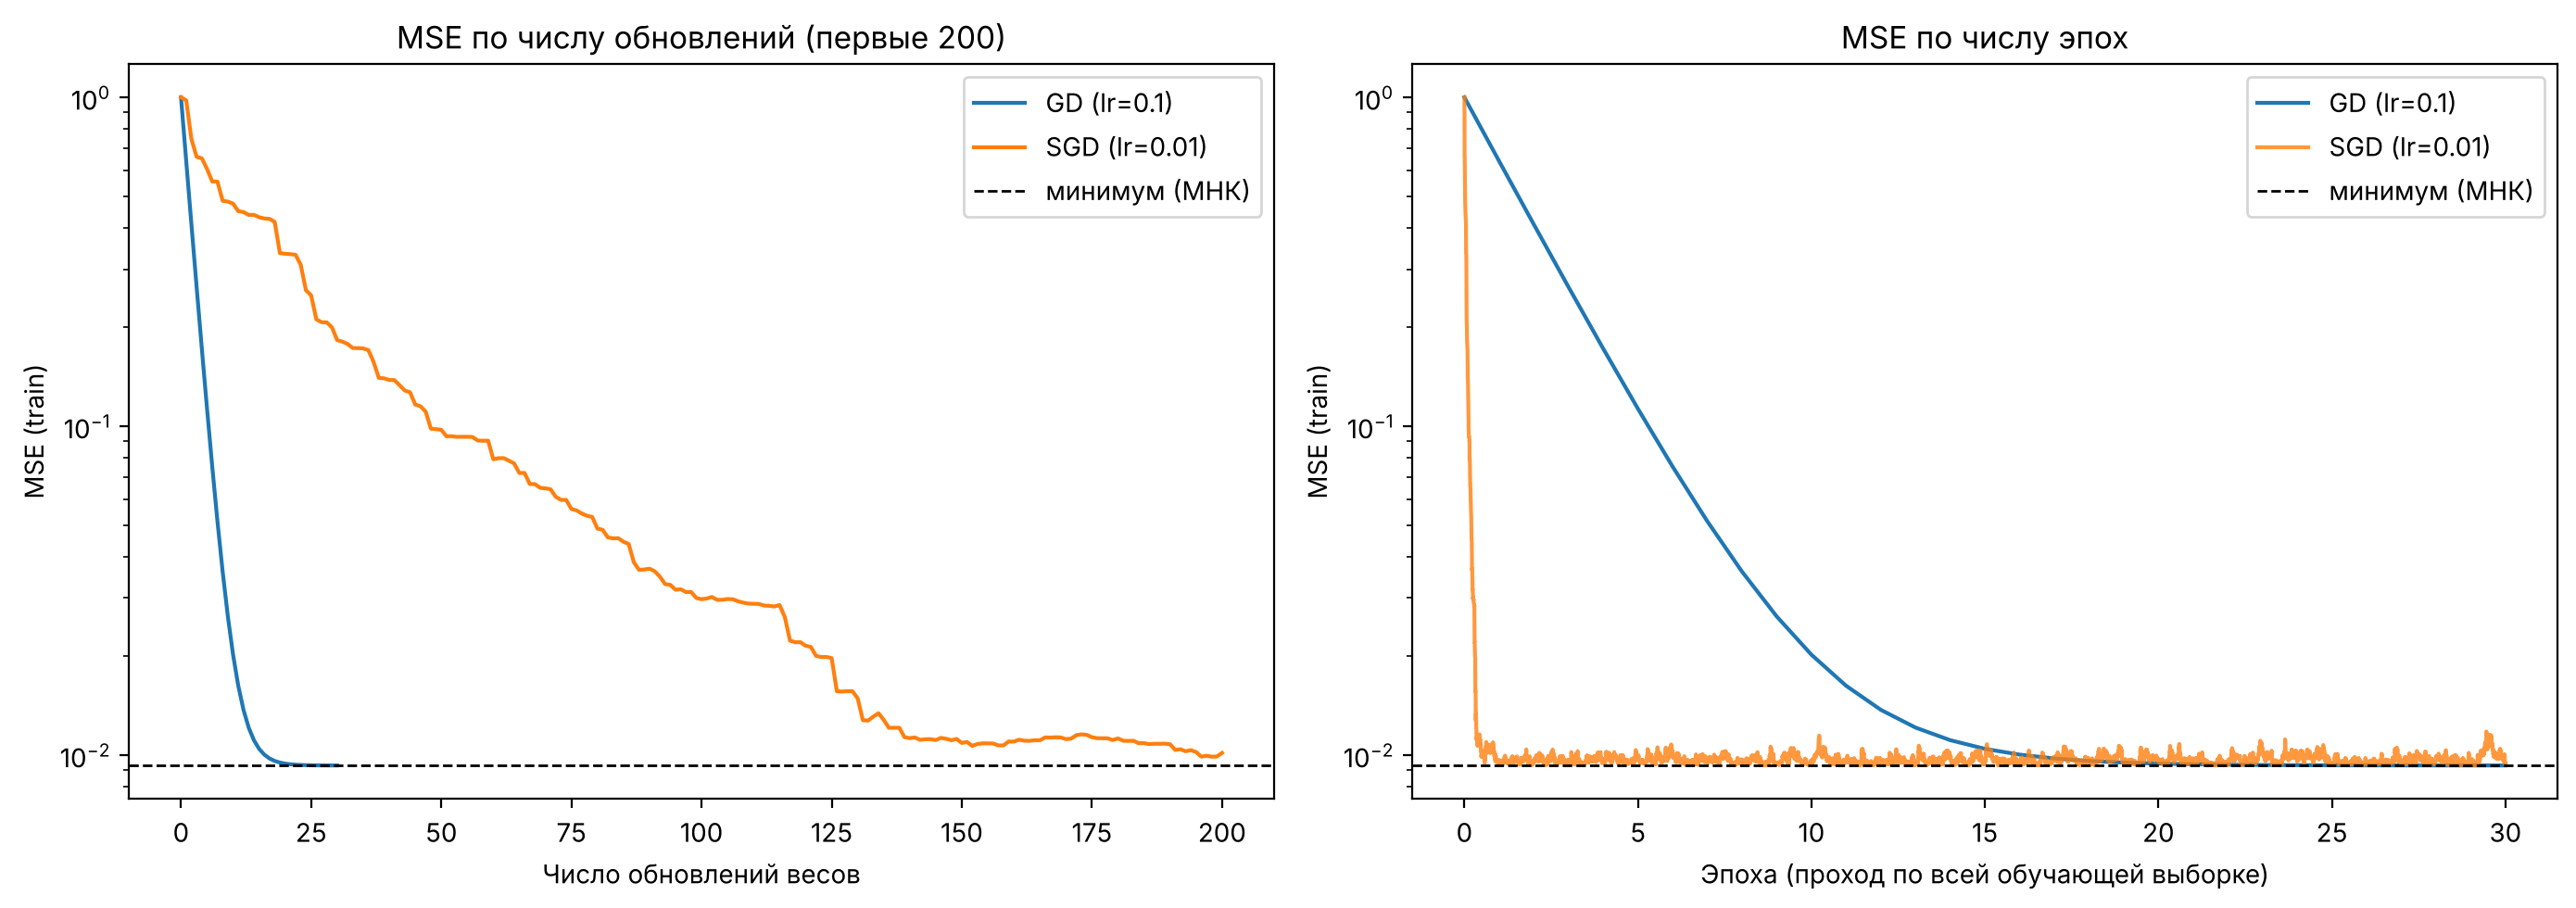

In [13]:
n_train = len(y_train_s)                             # число объектов в обучающей выборке (400)
eta_gd, eta_sgd = 0.1, 0.01                          # скорости обучения для GD и SGD
n_epochs = 30                                        # сколько эпох (проходов по данным) моделируем

w_gd5, mse_gd5 = gradient_descent(X_train_s, y_train_s, learning_rate=eta_gd, max_iter=n_epochs, epsilon=0)  # GD: 1 итерация = 1 эпоха; epsilon=0 - не останавливаться досрочно
w_sgd5, mse_sgd5 = stochastic_gradient_descent(X_train_s, y_train_s, learning_rate=eta_sgd,
                                               max_iter=n_epochs * n_train, epsilon=0)  # SGD: 30 эпох = 30*400 обновлений
mse_gd5, mse_sgd5 = np.array(mse_gd5), np.array(mse_sgd5)  # превращаем истории в массивы NumPy
mse_opt = mean_squared_error(y_train_s, lr.predict(X_train_s))   # минимум MSE (МНК)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))      # два графика в ряд
axes[0].plot(mse_gd5[:201], label=f'GD (lr={eta_gd})')    # левый график: MSE по числу обновлений, GD
axes[0].plot(mse_sgd5[:201], label=f'SGD (lr={eta_sgd})') # и SGD (первые 200 обновлений)
axes[0].set_xlabel('Число обновлений весов')               # подпись оси X
axes[0].set_title('MSE по числу обновлений (первые 200)')  # заголовок

epochs_gd = np.arange(len(mse_gd5))                  # ось X для GD: номер итерации = номер эпохи
epochs_sgd = np.arange(len(mse_sgd5)) / n_train      # ось X для SGD: делим на 400, чтобы получить эпохи
axes[1].plot(epochs_gd, mse_gd5, label=f'GD (lr={eta_gd})')                 # правый график: по эпохам, GD
axes[1].plot(epochs_sgd, mse_sgd5, label=f'SGD (lr={eta_sgd})', alpha=0.8)  # и SGD (чуть прозрачнее)
axes[1].set_xlabel('Эпоха (проход по всей обучающей выборке)')              # подпись оси X
axes[1].set_title('MSE по числу эпох')                                      # заголовок

for ax in axes:                                      # общие настройки для обоих графиков
    ax.axhline(mse_opt, color='k', ls='--', lw=1, label='минимум (МНК)')  # пунктир - минимально достижимая ошибка
    ax.set_yscale('log')                             # логарифмическая шкала по Y
    ax.set_ylabel('MSE (train)')                     # подпись оси Y
    ax.legend()                                      # легенда
plt.tight_layout()                                   # расставить элементы без наложений
plt.show()                                           # показать графики

In [14]:
def first_reach(hist, target):                       # номер первого шага, на котором ошибка опустилась до target
    idx = np.where(hist <= target)[0]                # индексы всех шагов, где MSE <= target
    return int(idx[0]) if len(idx) else None         # первый из них (или None, если не достигли)

target = mse_opt * 1.05   # в пределах 5% от минимума
upd_gd, upd_sgd = first_reach(mse_gd5, target), first_reach(mse_sgd5, target)  # за сколько обновлений дошёл каждый метод
print(f'MSE <= 1.05 * MSE_min: GD -> {upd_gd} обновлений ({upd_gd} эпох); '
      f'SGD -> {upd_sgd} обновлений ({upd_sgd / n_train:.2f} эпохи)')  # сравнение по обновлениям и по эпохам

pd.DataFrame([                                       # итоговая таблица: ошибки на train и test
    {'метод': 'GD', 'train MSE': mse_gd5[-1], 'test MSE': mean_squared_error(y_test_s, np.column_stack([np.ones(len(X_test_s)), X_test_s]) @ w_gd5)},   # GD
    {'метод': 'SGD', 'train MSE': mse_sgd5[-1], 'test MSE': mean_squared_error(y_test_s, np.column_stack([np.ones(len(X_test_s)), X_test_s]) @ w_sgd5)}, # SGD
    {'метод': 'МНК', 'train MSE': mse_opt, 'test MSE': mean_squared_error(y_test_s, lr.predict(X_test_s))},  # эталон
]).round(5)                                          # округляем до 5 знаков

MSE <= 1.05 * MSE_min: GD -> 18 обновлений (18 эпох); SGD -> 230 обновлений (0.57 эпохи)


,метод,train MSE,test MSE
0,GD,0.00929,0.01005
1,SGD,0.00943,0.00992
2,МНК,0.00929,0.01007


**Выводы по заданию 5**

- **По числу обновлений весов** пакетный GD сходится быстрее: до 5% от минимума MSE ему нужно 18 обновлений, SGD (с меньшим шагом 0.01) — около 230. Каждое обновление GD использует точный градиент по всей выборке, а SGD — шумную оценку по одному объекту, поэтому его траектория «ступенчатая» и менее направленная.
- **По числу эпох (затратам вычислений)** картина обратная: SGD достигает той же точности менее чем за одну эпоху (≈0.57), а GD на это нужно 18 эпох, т.е. 18 полных проходов по данным. Одно обновление GD стоит $n$ вычислений градиента объекта, а SGD — одно, так что на больших выборках SGD заметно выгоднее.
- **Характер сходимости.** GD гладко и монотонно приближается к минимуму и останавливается точно в нём (MSE 0.00929 = МНК). SGD после быстрого спада не сходится в точку, а продолжает колебаться возле минимума (на графике эпох — «шум» около уровня 0.01), потому что при постоянном шаге каждый случайный объект тянет веса в свою сторону. Для точной сходимости шаг SGD нужно уменьшать по ходу обучения.
- **Качество на тесте** у обоих методов практически одинаковое (≈0.0100 против МНК 0.0101), то есть небольшие колебания SGD на обобщающую способность модели не влияют.

Итого: GD точнее и стабильнее, SGD быстрее на первых этапах и дешевле на итерацию, но даёт «шумное» решение вблизи оптимума.

### Задание 6
Вариант 7 — нечётный, поэтому реализуем **L2-регуляризацию** (гребневая регрессия). К функции потерь добавляется штраф на веса признаков:

$L(w) = \frac1n\sum_i (\hat y_i - y_i)^2 + \alpha \sum_{j\ge1} w_j^2$, $\quad \nabla L = \frac2n X^T(Xw - y) + 2\alpha\,w$ (для $j\ge1$).

Свободный член $w_0$ не штрафуется. Затем возьмём 20 значений $\alpha$ в диапазоне от 0.001 до 1000 (равномерно в логарифмической шкале) и покажем, как меняются веса.

In [15]:
def gradient_descent_l2(X, y, alpha=0.0, learning_rate=0.1, max_iter=5000, epsilon=1e-10):
    # градиентный спуск с L2-регуляризацией; alpha - сила штрафа за большие веса
    Xb = np.column_stack([np.ones(len(X)), X])       # столбец единиц для свободного члена w0
    w = np.zeros(Xb.shape[1])                        # начальные веса - нули
    for i in range(max_iter):                        # цикл по итерациям
        grad = 2 / len(y) * Xb.T @ (Xb @ w - y)      # обычный градиент MSE
        grad[1:] += 2 * alpha * w[1:]          # L2-штраф, w0 не штрафуется
        w_new = w - learning_rate * grad             # шаг градиентного спуска
        converged = np.linalg.norm(w_new - w) < epsilon  # веса почти не изменились?
        w = w_new                                    # принимаем новые веса
        if converged:                                # если сошлись -
            break                                    # выходим из цикла
    return w, i + 1                                  # возвращаем веса и число выполненных итераций

In [16]:
alphas = np.logspace(-3, 3, 20)               # 20 значений от 0.001 до 1000
Xb_train = np.column_stack([np.ones(n_train), X_train_s])  # матрица признаков со столбцом единиц
lam_max = np.linalg.eigvalsh(2 / n_train * Xb_train.T @ Xb_train).max()  # наибольшее собственное число гессиана MSE (определяет допустимый шаг)

weights_l2, n_iters = [], []                         # сюда будем складывать веса и число итераций для каждого alpha
for a in alphas:                                     # перебираем коэффициенты регуляризации
    eta = 1 / (lam_max + 2 * a)               # шаг, гарантирующий устойчивость при любом alpha
    w, k = gradient_descent_l2(X_train_s, y_train_s, alpha=a, learning_rate=eta)  # обучаем модель с данным alpha
    weights_l2.append(w)                             # запоминаем найденные веса
    n_iters.append(k)                                # и число итераций
weights_l2 = np.array(weights_l2)                    # список весов -> матрица 20x4

# проверка по аналитическому решению гребневой регрессии
ridge_exact = []                                     # точные веса гребневой регрессии для каждого alpha
for a in alphas:                                     # для каждого alpha решаем линейную систему
    A = Xb_train.T @ Xb_train / n_train + a * np.diag([0, 1, 1, 1])  # матрица системы (w0 не штрафуем - нуль в диагонали)
    ridge_exact.append(np.linalg.solve(A, Xb_train.T @ y_train_s / n_train))  # решение системы A*w = b
print('Макс. отклонение GD от аналитического решения:', np.abs(weights_l2 - np.array(ridge_exact)).max())  # должно быть почти 0

table = pd.DataFrame(weights_l2, columns=['w0', 'w1', 'w2', 'w3'])  # таблица весов
table.insert(0, 'alpha', alphas)                     # слева добавляем столбец со значениями alpha
table['итераций'] = n_iters                          # и столбец с числом итераций
table.round(4)                                       # выводим таблицу, округлив до 4 знаков

Макс. отклонение GD от аналитического решения: 4.472533454702443e-12


,alpha,w0,w1,w2,w3,итераций
0,0.0010,-0.0,0.2409,0.8107,0.5133,9
1,0.0021,-0.0,0.2407,0.8098,0.5128,9
2,0.0043,-0.0,0.2401,0.8080,0.5117,9
3,0.0089,-0.0,0.2389,0.8044,0.5094,9
4,0.0183,-0.0,0.2366,0.7969,0.5049,9
5,0.0379,-0.0,0.2318,0.7820,0.4957,9
6,0.0785,-0.0,0.2225,0.7527,0.4777,9
7,0.1624,-0.0,0.2055,0.6987,0.4443,9
8,0.3360,-0.0,0.1774,0.6083,0.3881,9
9,0.6952,-0.0,0.1383,0.4799,0.3077,8


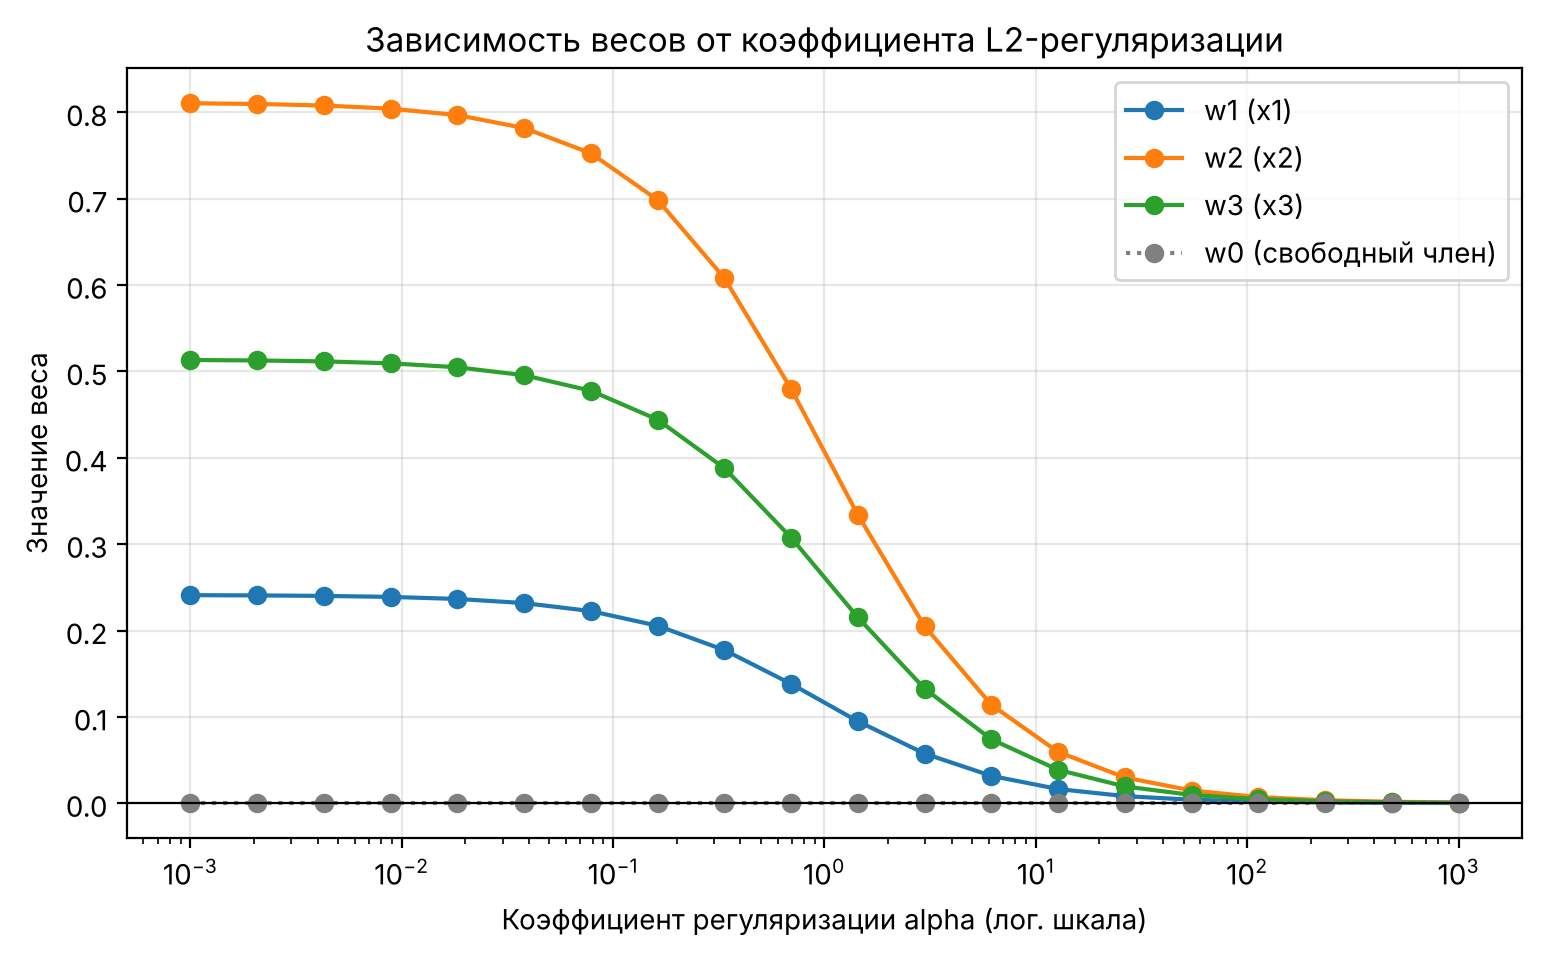

In [17]:
plt.figure(figsize=(9, 5))                           # новый график
for j, name in enumerate(['w1 (x1)', 'w2 (x2)', 'w3 (x3)'], start=1):  # по очереди рисуем веса при признаках (столбцы 1..3)
    plt.plot(alphas, weights_l2[:, j], marker='o', label=name)          # линия веса в зависимости от alpha
plt.plot(alphas, weights_l2[:, 0], marker='o', ls=':', color='gray', label='w0 (свободный член)')  # свободный член (серый пунктир)
plt.xscale('log')                                    # логарифмическая шкала по X: alpha меняется на порядки
plt.axhline(0, color='k', lw=0.8)                    # горизонтальная линия на нуле
plt.xlabel('Коэффициент регуляризации alpha (лог. шкала)')  # подпись оси X
plt.ylabel('Значение веса')                          # подпись оси Y
plt.title('Зависимость весов от коэффициента L2-регуляризации')  # заголовок
plt.legend()                                         # легенда
plt.grid(True, alpha=0.3)                            # слабая сетка для удобства чтения
plt.show()                                           # показать график

**Выводы по заданию 6**

- Найденные градиентным спуском веса совпадают с аналитическим решением гребневой регрессии (отклонение ≈$4\cdot10^{-12}$), то есть реализация L2-штрафа корректна.
- При малых $\alpha$ (≈0.001) веса почти равны весам обычной регрессии: $w \approx (0.241,\ 0.811,\ 0.513)$. Штраф слишком слаб, чтобы повлиять на решение.
- При росте $\alpha$ веса монотонно и плавно уменьшаются по модулю. Заметное сжатие начинается около $\alpha \approx 0.1$–$1$ (при $\alpha = 1.44$ веса уже втрое-вчетверо меньше исходных), а при $\alpha = 1000$ они практически равны нулю ($\approx 10^{-4}$–$10^{-3}$).
- Знаки весов сохраняются, а порядок по величине ($|w_2| > |w_3| > |w_1|$) остаётся тем же: L2 уменьшает все веса пропорционально, но **не обнуляет** их точно (в отличие от L1). Свободный член $w_0$ не штрафуется и остаётся ≈0, так как данные центрированы.
- Практический смысл: сильная регуляризация делает модель менее чувствительной к шуму и коррелированным признакам, но при слишком большом $\alpha$ она вырождается в константу (недообучение). Значение $\alpha$ следует подбирать по качеству на валидации.

## Общий вывод

В работе реализованы пакетный и стохастический градиентный спуск для линейной регрессии и проверены на синтетическом датасете. Скорость обучения определяет сходимость: слишком малая — медленно, слишком большая (η > 2/λmax) — расходимость. SGD дешевле по вычислениям на одно обновление и быстрее по числу эпох, но даёт «шумное» решение вблизи минимума, тогда как GD сходится гладко и точно. L2-регуляризация плавно уменьшает веса при росте коэффициента α, не обнуляя их.